In [299]:
import numpy as np 
import pandas as pd 
import pickle
import joblib
from pathlib import Path

# pipeline
from sklearn.pipeline import Pipeline

# knn
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import GridSearchCV, train_test_split

import matplotlib.pyplot as plt
DATA_dir = Path("../data")

In [300]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(y_true, y_pred, model_name="Model"):
    print(f"===== {model_name} =====")
    print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_true, y_pred):.4f}")
    print(f"F1-score : {f1_score(y_true, y_pred):.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [301]:
X_train_processed = np.load(DATA_dir / "X_train_processed.npy")
X_test_processed = np.load(DATA_dir / "X_test_processed.npy")

y_train = pd.read_csv(DATA_dir / "y_train.csv")
y_test = pd.read_csv(DATA_dir / "y_test.csv")


feature_names = joblib.load(DATA_dir / "feature_names.pkl")
class_weight = joblib.load(DATA_dir / "class_weight.pkl")

print(type(feature_names))
print(feature_names[:10])

print(type(class_weight))
print(class_weight)


<class 'numpy.ndarray'>
['num__SeniorCitizen' 'num__tenure' 'num__MonthlyCharges'
 'num__TotalCharges' 'cat__gender_Male' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service']
<class 'dict'>
{np.int64(0): np.float64(0.6805991785455424), np.int64(1): np.float64(1.8842809364548494)}


In [302]:
print("X_train:", X_train_processed.shape)
print("X_test :", X_test_processed.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634, 1)
y_test : (1409, 1)
Number of features: 40


In [303]:
assert X_train_processed.shape[0] == y_train.shape[0]
assert X_test_processed.shape[0] == y_test.shape[0]
assert X_train_processed.shape[1] == len(feature_names)

print("Shape alignment OK")

Shape alignment OK


In [304]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

y_train shape: (5634,)
y_test shape : (1409,)


In [305]:
print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

Train labels: [0 1]
Test labels : [0 1]


In [306]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [307]:
print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


# KNN

KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới
      ↓
① Tính khoảng cách với khách trong train
      ↓
② Tìm K người gần nhất
      ↓
③ Xem họ thuộc class 0 hay 1
      ↓
④ Majority vote
      ↓
Dự đoán Churn / No Churn

# KNN Baseline

In [308]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train_processed, y_train) # train

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [309]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

In [310]:
# kiem thu 10 ket qua dau tien
print(f"Prediction: {y_predict_knn_baseline[:10]}")
print(f"Acutal: {y_test.iloc[:10].values}")


Prediction: [0 1 0 1 0 1 0 0 0 0]
Acutal: [0 0 0 0 0 0 0 0 0 1]


Đánh giá KNN baseline 
| Metric    | Câu hỏi nó trả lời                                          |
| --------- | ----------------------------------------------------------- |
| Accuracy  | Tổng thể model đoán đúng bao nhiêu %?                       |
| Precision | Những người model báo churn, bao nhiêu người thực sự churn? |
| Recall    | Những người thực sự churn, model bắt được bao nhiêu?        |
| F1-score  | Cân bằng Precision và Recall                                |
| ROC-AUC   | Model phân biệt churn và non-churn tốt đến đâu?             |

0.5  → gần như random
0.6  → yếu
0.7  → khá
0.8  → tốt
0.9+ → rất tốt
1.0  → hoàn hảo

In [311]:
evaluate_model(y_test, y_predict_knn_baseline, "KNN Baseline")

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


1. trong 100 khách -> model dự đoán trúnga 76 khách
2. model cảnh báo 100 khách -> 54 churn thực sự
3. 100 người churn -> model phát hiện được 53 người
4. 
5. yếu

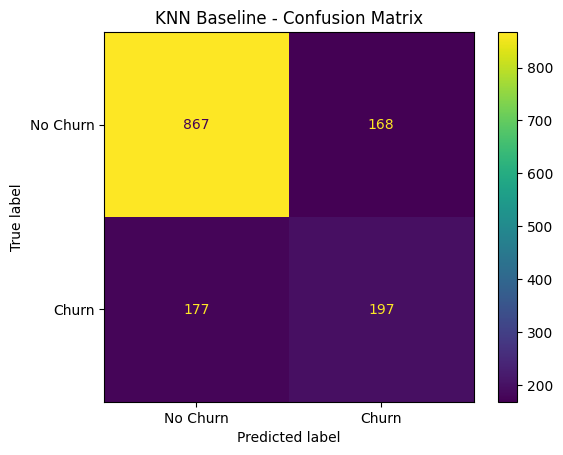

In [312]:
cm_knn_baseline = confusion_matrix(y_test,y_predict_knn_baseline)
display = ConfusionMatrixDisplay(
  confusion_matrix=cm_knn_baseline,
  display_labels=["No Churn", "Churn"]
)

display.plot()
plt.title("KNN Baseline - Confusion Matrix")
plt.show()

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

---

>  *Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ*

# TUNE KNN 

- K = 5 ? 
- K quá nhỏ -> nhạy với noise -> overfiting 
- K quá lớn -> quá rộng -> mất pattern toàn cục
---
*cần tìm k phù hợp*
--- 
X_train -> Cross-validation -> thử K khác nhau -> chọn best K -> train best model -> X_test <- chỉ đánh giá cuối cùng


In [313]:
df_raw = pd.read_csv(
    DATA_dir / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"],
    errors="coerce"
)

df_raw["TotalCharges"] = df_raw["TotalCharges"].fillna(0)

df_raw["Churn"] = df_raw["Churn"].map({
    "Yes": 1,
    "No": 0
})

X_raw = df_raw.drop(columns=["customerID", "Churn"])
y_raw = df_raw["Churn"]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    stratify=y_raw,
    random_state=42
)

print(X_train_raw.shape)
print(X_test_raw.shape)

(5634, 19)
(1409, 19)


In [314]:
# 1. Kiểm tra y trước
import numpy as np

y_train_file = np.asarray(y_train).ravel()
y_test_file = np.asarray(y_test).ravel()

y_train_raw_arr = np.asarray(y_train_raw).ravel()
y_test_raw_arr = np.asarray(y_test_raw).ravel()

print("=== TARGET ===")
print("Train same:", np.array_equal(y_train_file, y_train_raw_arr))
print("Test same :", np.array_equal(y_test_file, y_test_raw_arr))

print("=== SHAPE ===")
print("Processed train:", X_train.shape)
print("Processed test :", X_test.shape)

print("Raw train:", X_train_raw.shape)
print("Raw test :", X_test_raw.shape)

X_train_raw_processed = preprocessor.fit_transform(X_train_raw)
X_test_raw_processed = preprocessor.transform(X_test_raw)

# Nếu sparse matrix thì chuyển sang array
if hasattr(X_train_raw_processed, "toarray"):
    X_train_raw_processed = X_train_raw_processed.toarray()

if hasattr(X_test_raw_processed, "toarray"):
    X_test_raw_processed = X_test_raw_processed.toarray()

print("=== AFTER PREPROCESS ===")
print("Raw -> processed train:", X_train_raw_processed.shape)
print("File processed train  :", X_train.shape)

print("Raw -> processed test :", X_test_raw_processed.shape)
print("File processed test   :", X_test.shape)

print("=== VALUES ===")

print(
    "Train same:",
    np.allclose(
        X_train,
        X_train_raw_processed,
        rtol=1e-5,
        atol=1e-8
    )
)

print(
    "Test same:",
    np.allclose(
        X_test,
        X_test_raw_processed,
        rtol=1e-5,
        atol=1e-8
    )
)

print(
    "Train max difference:",
    np.max(np.abs(X_train - X_train_raw_processed))
)

print(
    "Test max difference:",
    np.max(np.abs(X_test - X_test_raw_processed))
)

=== TARGET ===
Train same: True
Test same : True
=== SHAPE ===
Processed train: (5634, 40)
Processed test : (1409, 40)
Raw train: (5634, 19)
Raw test : (1409, 19)
=== AFTER PREPROCESS ===
Raw -> processed train: (5634, 40)
File processed train  : (5634, 40)
Raw -> processed test : (1409, 40)
File processed test   : (1409, 40)
=== VALUES ===
Train same: True
Test same: True
Train max difference: 0.0
Test max difference: 0.0


In [315]:
preprocessor = preprocessing_pipeline.named_steps["preprocessor"]
knn_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("knn", KNeighborsClassifier())
])

param_grid = {
  "knn__n_neighbors": [3,5,7,9,11,15,21,25]
}
grid_knn = GridSearchCV(
  estimator=knn_pipeline,
  param_grid=param_grid,
  scoring="f1",
  cv=5,
  n_jobs=1
)

grid_knn.fit(X_train_raw, y_train_raw)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': [3, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candidate pa

In [316]:
print("Best params:", grid_knn.best_params_)
print("Best CV score:", grid_knn.best_score_)

Best params: {'knn__n_neighbors': 21}
Best CV score: 0.6056204608832034


> Qua cross-validation trên tập train, KNN với 21 neighbors đạt F1 trung bình ≈ 0.606 (60.56%), cao nhất trong các giá trị k được thử.

In [317]:
best_knn = grid_knn.best_estimator_
y_predict_knn_tuned = best_knn.predict(X_test_raw)

In [318]:
evaluate_model(y_test_raw,y_predict_knn_tuned , "KNN Tuned")

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


In [319]:
def compare_predictions(y_true, predictions):
    rows = []

    for model_name, y_pred in predictions.items():
        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()

        rows.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1-score": f1_score(y_true, y_pred),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

    return pd.DataFrame(rows).round(4)

In [320]:
knn_comparison = compare_predictions(
    y_test,
    {
        "KNN Baseline": y_predict_knn_baseline,
        "KNN Tuned": y_predict_knn_tuned
    }
)

knn_comparison

,Model,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,KNN Baseline,0.7551,0.5397,0.5267,0.5332,867,168,177,197
1,KNN Tuned,0.7835,0.5940,0.5829,0.5884,886,149,156,218


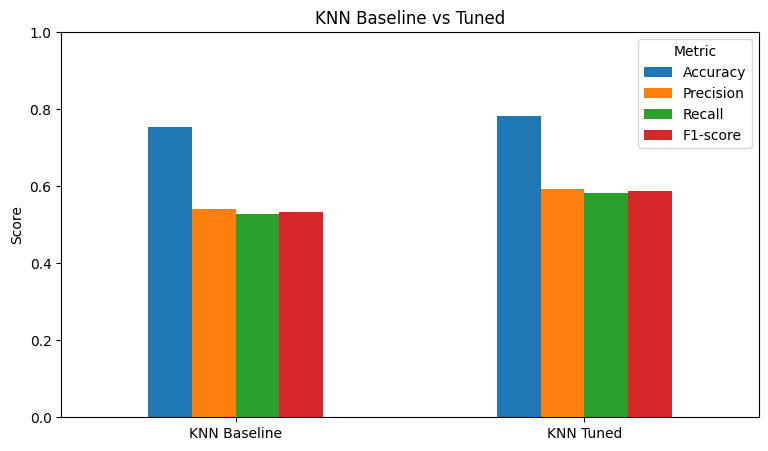

In [321]:
comparison_plot = knn_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("KNN Baseline vs Tuned")
plt.ylabel("Score")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.show()

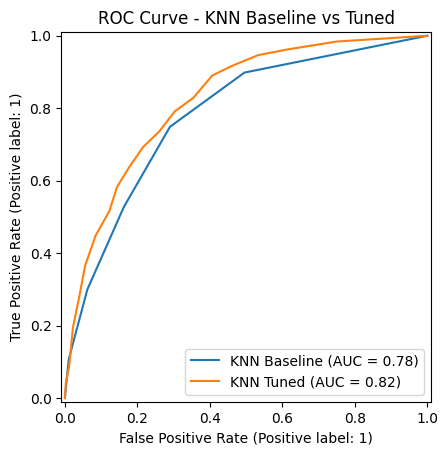

In [322]:
from sklearn.metrics import RocCurveDisplay

y_prob_knn_baseline = knn_baseline.predict_proba(X_test)[:, 1]
y_prob_knn_tuned = grid_knn.best_estimator_.predict_proba(X_test_raw)[:, 1]

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_knn_baseline,
    name="KNN Baseline"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_knn_tuned,
    name="KNN Tuned",
    ax=plt.gca()
)

plt.title("ROC Curve - KNN Baseline vs Tuned")
plt.show()